# Phase I metabolism of paracetamol

In [1]:
import drug_toxicity
from drug_toxicity import Predictor
predictor = Predictor()

We will use acetaminophen, also known as paracetamol, as an example drug. RDKit can be used to display the molecule:

## Running phase I and phase II separately

In [3]:
from rdkit import Chem
compound = "CC(=O)NC1=CC=C(C=C1)O"
molecule = Chem.MolFromSmiles(compound)

Then run the predictor. Note that when a reaction is unable take place for the compound, an error is thrown. This is not a problem, and the code will simply go to the next reaction.

In [5]:
phase_I_prods = predictor.predict_phase_i(compound)
phase_I_prods = list(set(phase_I_prods)) # ensure that there are no repetitions

[12:45:35] reactant 1 has no mapped atoms.
[12:45:35] reactant 1 has no mapped atoms.
[12:45:35] reactant 1 has no mapped atoms.
[12:45:35] reactant 1 has no mapped atoms.
[12:45:35] reactant 1 has no mapped atoms.
[12:45:35] reactant 1 has no mapped atoms.
[12:45:35] reactant 1 has no mapped atoms.
[12:45:35] reactant 1 has no mapped atoms.
[12:45:35] reactant 1 has no mapped atoms.
[12:45:35] reactant 1 has no mapped atoms.
[12:45:35] Explicit valence for atom # 1 C, 5, is greater than permitted


O=C(CO)Nc1ccc(O)cc1
CC(=O)Nc1ccc(O)cc1O
CC(=O)Nc1ccc(O)c(O)c1


[12:45:37] Can't kekulize mol.  Unkekulized atoms: 7 8 9 11 12
[12:45:37] Can't kekulize mol.  Unkekulized atoms: 4 5 6 11 12


CC(=O)Nc1ccc(O)cc1O
CC(=O)Nc1ccc(O)c(O)c1
CC(=O)N(O)c1ccc(O)cc1
CC(N)=O


[12:45:39] Can't kekulize mol.  Unkekulized atoms: 2 3 4 6 7


Nc1ccc(O)cc1


[12:45:39] Explicit valence for atom # 1 C, 5, is greater than permitted
[12:45:39] Explicit valence for atom # 1 C, 5, is greater than permitted
[12:45:39] Can't kekulize mol.  Unkekulized atoms: 2 3 4 6 7


Nc1ccc(O)cc1
CC(N)=O
CC(=O)N=C1C=CC(=O)C=C1
CC(=O)O
Nc1ccc(O)cc1
CO
O=CNc1ccc(O)cc1
O=C(O)Nc1ccc(O)cc1
C
CC(=O)O
Nc1ccc(O)cc1
Oc1ccc(O)cc1
CC(N)=O
CC(=O)O
Nc1ccc(O)cc1


[12:45:44] Can't kekulize mol.  Unkekulized atoms: 4 5 6 9 10


The list ```phase_I_prods``` gives the products of phase I metabolism as a list of metabolites in SMILES format. These can be displayed using RDKit:

In [ ]:
from rdkit.Chem import Draw
products_I = [Chem.MolFromSmiles(x.smiles) for x in phase_I_prods]
img_I = Draw.MolsToGridImage(products_I, returnPNG=True, molsPerRow=5)

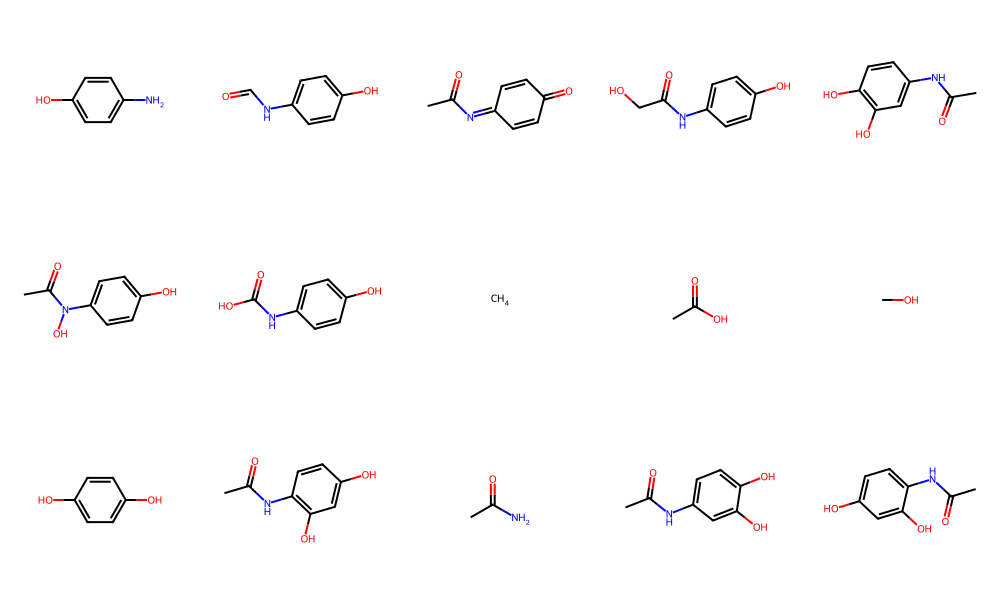

In [7]:
img

The workflow for phase II metabolism is very similar. Either one metabolite, or a list or metabolites, from phase I metabolism can be inputted.

In [9]:
phase_II_prods = predictor.predict_phase_ii(phase_I_prods)
phase_II_prods = list(set(phase_II_prods)) # ensure no repetitions


[12:47:11] reactant 1 has no mapped atoms.
[12:47:11] reactant 1 has no mapped atoms.
[12:47:11] reactant 1 has no mapped atoms.
[12:47:11] reactant 1 has no mapped atoms.
[12:47:11] reactant 1 has no mapped atoms.
[12:47:11] reactant 1 has no mapped atoms.
[12:47:11] reactant 1 has no mapped atoms.
[12:47:11] reactant 1 has no mapped atoms.
[12:47:11] reactant 1 has no mapped atoms.
[12:47:11] reactant 1 has no mapped atoms.
[12:47:11] reactant 1 has no mapped atoms.
[12:47:11] reactant 1 has no mapped atoms.
[12:47:11] reactant 1 has no mapped atoms.
[12:47:11] reactant 1 has no mapped atoms.
[12:47:11] reactant 1 has no mapped atoms.
[12:47:11] reactant 1 has no mapped atoms.
[12:47:11] reactant 1 has no mapped atoms.
[12:47:11] reactant 1 has no mapped atoms.
[12:47:11] reactant 1 has no mapped atoms.
[12:47:11] reactant 1 has no mapped atoms.
[12:47:11] reactant 1 has no mapped atoms.
[12:47:11] reactant 1 has no mapped atoms.
[12:47:11] reactant 1 has no mapped atoms.
[12:47:11] 

Nc1ccc(OC2OC(C(=O)O)C(O)C(O)C2O)cc1
O=C(O)C1OC(Nc2ccc(O)cc2)C(O)C(O)C1O
Nc1ccc(O[SH](=O)([O-])O)cc1
CN(C)c1ccc(O)cc1
CC(=O)Nc1ccc(O)cc1
O=CNc1ccc(OC2OC(C(=O)O)C(O)C(O)C2O)cc1
O=CN(c1ccc(O)cc1)C1OC(C(=O)O)C(O)C(O)C1O
O=CNc1ccc(O[SH](=O)([O-])O)cc1
CN(C=O)c1ccc(O)cc1
CC(=O)N(C=O)c1ccc(O)cc1


[12:47:15] Explicit valence for atom # 7 N, 4, is greater than permitted


CC(=O)N=C1C=CC(=O)C=C1SC(NC(=O)CCC([NH3+])C(=O)[O-])C(=O)NCC(=O)O


[12:47:16] Explicit valence for atom # 3 N, 5, is greater than permitted
[12:47:16] Explicit valence for atom # 3 N, 4, is greater than permitted


O=C(COC1OC(C(=O)O)C(O)C(O)C1O)Nc1ccc(O)cc1
O=C(CO)Nc1ccc(OC2OC(C(=O)O)C(O)C(O)C2O)cc1
O=C(O)C1OC(N(C(=O)CO)c2ccc(O)cc2)C(O)C(O)C1O
O=C(CO[SH](=O)([O-])O)Nc1ccc(O)cc1
O=C(CO)Nc1ccc(O[SH](=O)([O-])O)cc1
CN(C(=O)CO)c1ccc(O)cc1
CC(=O)N(C(=O)CO)c1ccc(O)cc1
CC(=O)Nc1ccc(O)c(OC2OC(C(=O)O)C(O)C(O)C2O)c1
CC(=O)Nc1ccc(OC2OC(C(=O)O)C(O)C(O)C2O)c(O)c1
CC(=O)N(c1ccc(O)c(O)c1)C1OC(C(=O)O)C(O)C(O)C1O
CC(=O)Nc1ccc(O)c(O[SH](=O)([O-])O)c1
CC(=O)Nc1ccc(O[SH](=O)([O-])O)c(O)c1
COc1ccc(NC(C)=O)cc1O
COc1cc(NC(C)=O)ccc1O
CC(=O)N(C)c1ccc(O)c(O)c1
CC(=O)N(C(C)=O)c1ccc(O)c(O)c1
CC(=O)N(O)c1ccc(OC2OC(C(=O)O)C(O)C(O)C2O)cc1


[12:47:26] Explicit valence for atom # 7 N, 4, is greater than permitted


CC(=O)N(O)c1ccc(O[SH](=O)([O-])O)cc1


[12:47:26] Explicit valence for atom # 3 N, 4, is greater than permitted
[12:47:26] Explicit valence for atom # 3 N, 4, is greater than permitted


O=C(Nc1ccc(O)cc1)OC1OC(C(=O)O)C(O)C(O)C1O
O=C(O)Nc1ccc(OC2OC(C(=O)O)C(O)C(O)C2O)cc1
O=C(Nc1ccc(O)cc1)OC1OC(C(=O)O)C(O)C(O)C1O
O=C(O)C1OC(N(C(=O)O)c2ccc(O)cc2)C(O)C(O)C1O
O=C(Nc1ccc(O)cc1)O[SH](=O)([O-])O
O=C(O)Nc1ccc(O[SH](=O)([O-])O)cc1
CN(C(=O)O)c1ccc(O)cc1
CC(=O)N(C(=O)O)c1ccc(O)cc1
CC(=O)OC1OC(C(=O)O)C(O)C(O)C1O
CC(=O)OC1OC(C(=O)O)C(O)C(O)C1O
CC(=O)O[SH](=O)([O-])O
CC(=O)NCC(=O)O
CC(=O)NC(CCC(N)=O)C(=O)O
CC(=O)NCCS(=O)(=O)[O-]
COC1OC(C(=O)O)C(O)C(O)C1O
CO[SH](=O)([O-])O
O=C(O)C1OC(Oc2ccc(O)cc2)C(O)C(O)C1O
O=[SH]([O-])(O)Oc1ccc(O)cc1
CC(=O)Nc1ccc(O)cc1OC1OC(C(=O)O)C(O)C(O)C1O
CC(=O)Nc1ccc(OC2OC(C(=O)O)C(O)C(O)C2O)cc1O
CC(=O)N(c1ccc(O)cc1O)C1OC(C(=O)O)C(O)C(O)C1O
CC(=O)Nc1ccc(O)cc1O[SH](=O)([O-])O
CC(=O)Nc1ccc(O[SH](=O)([O-])O)cc1O
CC(=O)N(C)c1ccc(O)cc1O
CC(=O)N(C(C)=O)c1ccc(O)cc1O
CC(=O)NC1OC(C(=O)O)C(O)C(O)C1O
CC(=O)N(C)C
CC(=O)NC(C)=O
CC(=O)Nc1ccc(O)c(OC2OC(C(=O)O)C(O)C(O)C2O)c1
CC(=O)Nc1ccc(OC2OC(C(=O)O)C(O)C(O)C2O)c(O)c1
CC(=O)N(c1ccc(O)c(O)c1)C1OC(C(=O)O)C(O)C(O)C1O
CC(=O)Nc1cc

Again, the products can be displayed

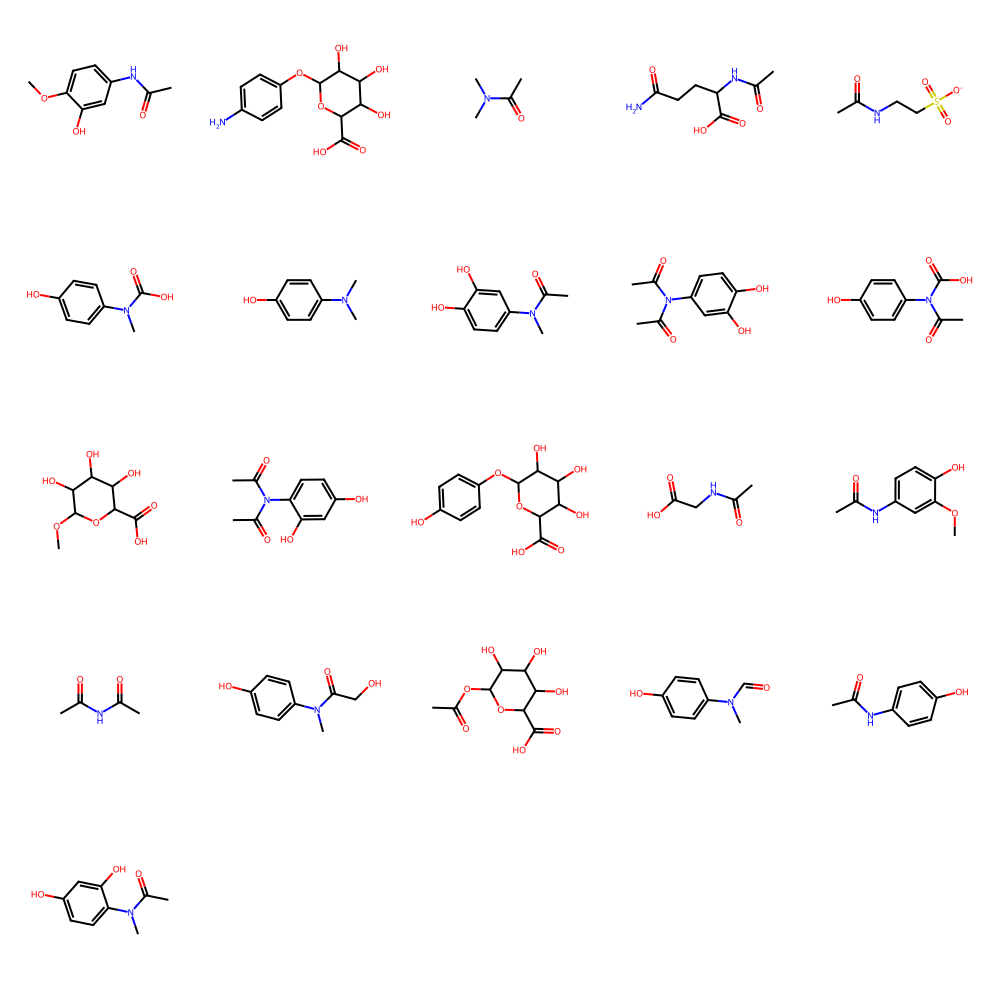

In [10]:
products_II = [Chem.MolFromSmiles(x.smiles) for x in phase_II_prods]
img_II = Draw.MolsToGridImage(products_II, returnPNG=True, molsPerRow=5)
img_II

## Running phase I and phase II together

If it is not of interest whether a metabolite comes from phase I or phase II metabolism, these may be run together using the ```predict_products``` function.

In [4]:
all_metabolites = drug_toxicity.predict_products(compound)
all_metabolites = list(set(all_metabolites)) # ensure no repetitions


[13:03:52] reactant 1 has no mapped atoms.
[13:03:52] reactant 1 has no mapped atoms.
[13:03:52] reactant 1 has no mapped atoms.
[13:03:52] reactant 1 has no mapped atoms.
[13:03:52] reactant 1 has no mapped atoms.
[13:03:52] reactant 1 has no mapped atoms.
[13:03:52] reactant 1 has no mapped atoms.
[13:03:52] reactant 1 has no mapped atoms.
[13:03:52] reactant 1 has no mapped atoms.
[13:03:52] reactant 1 has no mapped atoms.
[13:03:52] Explicit valence for atom # 1 C, 5, is greater than permitted


O=C(CO)Nc1ccc(O)cc1
CC(=O)Nc1ccc(O)cc1O
CC(=O)Nc1ccc(O)c(O)c1


[13:03:54] Can't kekulize mol.  Unkekulized atoms: 7 8 9 11 12
[13:03:54] Can't kekulize mol.  Unkekulized atoms: 4 5 6 11 12


CC(=O)Nc1ccc(O)cc1O
CC(=O)Nc1ccc(O)c(O)c1
CC(=O)N(O)c1ccc(O)cc1
CC(N)=O


[13:03:55] Can't kekulize mol.  Unkekulized atoms: 2 3 4 6 7


Nc1ccc(O)cc1


... (6 outputs left out)

[13:04:25] Explicit valence for atom # 3 N, 4, is greater than permitted
[13:04:25] Explicit valence for atom # 3 N, 4, is greater than permitted


CC(=O)NC1OC(C(=O)O)C(O)C(O)C1O
CC(=O)N(C)C
CC(=O)NC(C)=O
Nc1ccc(OC2OC(C(=O)O)C(O)C(O)C2O)cc1
O=C(O)C1OC(Nc2ccc(O)cc2)C(O)C(O)C1O
Nc1ccc(O[SH](=O)([O-])O)cc1
CN(C)c1ccc(O)cc1
CC(=O)Nc1ccc(O)cc1
Nc1ccc(OC2OC(C(=O)O)C(O)C(O)C2O)cc1
O=C(O)C1OC(Nc2ccc(O)cc2)C(O)C(O)C1O
Nc1ccc(O[SH](=O)([O-])O)cc1
CN(C)c1ccc(O)cc1
CC(=O)Nc1ccc(O)cc1
CC(=O)NC1OC(C(=O)O)C(O)C(O)C1O
CC(=O)N(C)C
CC(=O)NC(C)=O
CC(=O)N=C1C=CC(=O)C=C1SC(NC(=O)CCC([NH3+])C(=O)[O-])C(=O)NCC(=O)O


[13:04:33] Explicit valence for atom # 7 N, 4, is greater than permitted
[13:04:33] Explicit valence for atom # 3 N, 5, is greater than permitted
[13:04:33] Explicit valence for atom # 3 N, 4, is greater than permitted


CC(=O)OC1OC(C(=O)O)C(O)C(O)C1O
CC(=O)OC1OC(C(=O)O)C(O)C(O)C1O
CC(=O)O[SH](=O)([O-])O
CC(=O)NCC(=O)O
CC(=O)NC(CCC(N)=O)C(=O)O
CC(=O)NCCS(=O)(=O)[O-]
Nc1ccc(OC2OC(C(=O)O)C(O)C(O)C2O)cc1
O=C(O)C1OC(Nc2ccc(O)cc2)C(O)C(O)C1O
Nc1ccc(O[SH](=O)([O-])O)cc1
CN(C)c1ccc(O)cc1
CC(=O)Nc1ccc(O)cc1
COC1OC(C(=O)O)C(O)C(O)C1O
CO[SH](=O)([O-])O
O=CNc1ccc(OC2OC(C(=O)O)C(O)C(O)C2O)cc1
O=CN(c1ccc(O)cc1)C1OC(C(=O)O)C(O)C(O)C1O
O=CNc1ccc(O[SH](=O)([O-])O)cc1
CN(C=O)c1ccc(O)cc1
CC(=O)N(C=O)c1ccc(O)cc1
O=C(Nc1ccc(O)cc1)OC1OC(C(=O)O)C(O)C(O)C1O
O=C(O)Nc1ccc(OC2OC(C(=O)O)C(O)C(O)C2O)cc1
O=C(Nc1ccc(O)cc1)OC1OC(C(=O)O)C(O)C(O)C1O
O=C(O)C1OC(N(C(=O)O)c2ccc(O)cc2)C(O)C(O)C1O
O=C(Nc1ccc(O)cc1)O[SH](=O)([O-])O
O=C(O)Nc1ccc(O[SH](=O)([O-])O)cc1
CN(C(=O)O)c1ccc(O)cc1
CC(=O)N(C(=O)O)c1ccc(O)cc1
CC(=O)OC1OC(C(=O)O)C(O)C(O)C1O
CC(=O)OC1OC(C(=O)O)C(O)C(O)C1O
CC(=O)O[SH](=O)([O-])O
CC(=O)NCC(=O)O
CC(=O)NC(CCC(N)=O)C(=O)O
CC(=O)NCCS(=O)(=O)[O-]
Nc1ccc(OC2OC(C(=O)O)C(O)C(O)C2O)cc1
O=C(O)C1OC(Nc2ccc(O)cc2)C(O)C(O)C1O
Nc1ccc(O[SH

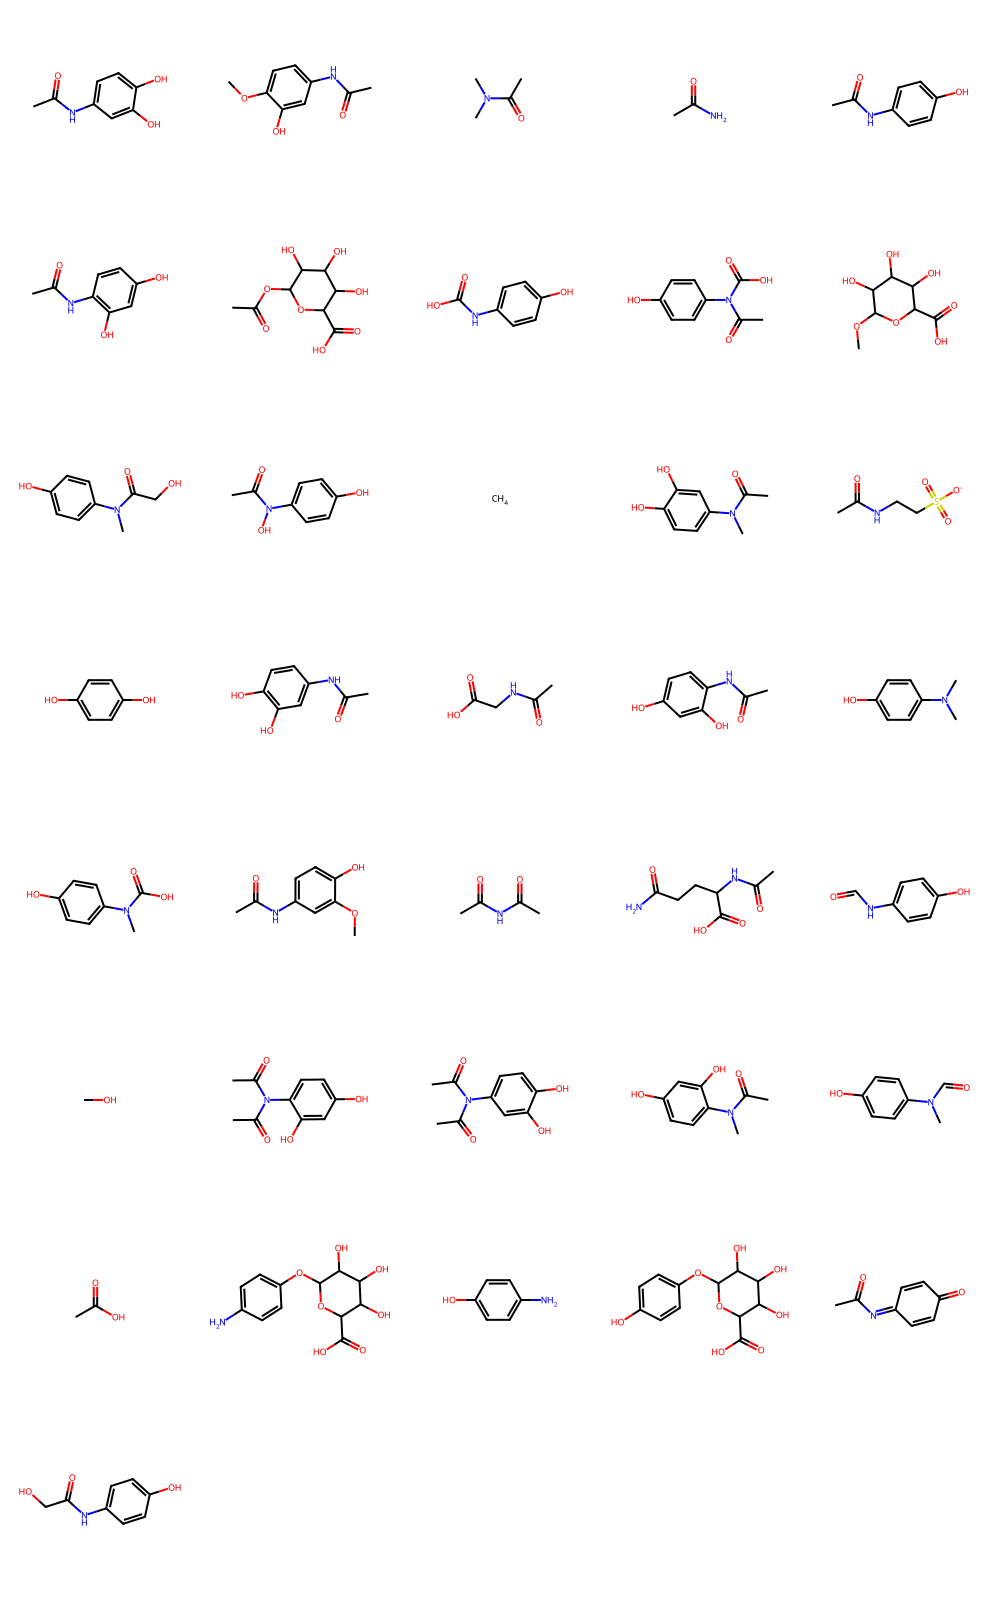

In [7]:
products = [Chem.MolFromSmiles(x.smiles) for x in all_metabolites]
img = Draw.MolsToGridImage(products, returnPNG=True, molsPerRow=5)
img